# Build and sample a quantum circuit

We will describe a small experiment in Qiskit, predict its outcomes, and sample
it locally. Then we will change the circuit and hand it to MQT Core.

Start with a fresh kernel and run the cells in order. This notebook uses the
same Python 3.15 environment as the rest of the tutorial. Qiskit's statevector
simulator is sufficient for these small circuits. No device account is needed.

**Notebook 01 · 40 minutes.** Build the Bell circuit and complete the GHZ
exercise. Predict the measurement outcomes before running each experiment.
Simulation is optional: use the saved probabilities and plots to discuss your
predictions if you prefer. Finish by importing the Bell circuit into MQT Core.

## Build a Bell circuit

Apply a Hadamard to qubit 0, then a controlled-X from qubit 0 to qubit 1.
Starting from $|00\rangle$, this prepares
$|\Phi^+\rangle=(|00\rangle+|11\rangle)/\sqrt{2}$.

Before running the simulation, predict which bitstrings can occur.

In [1]:
import sys
from importlib.metadata import version

import numpy as np
from IPython.display import Code, display
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_distribution

print("Python:", sys.version.split()[0])
print("Qiskit:", version("qiskit"))
print("MQT Core:", version("mqt-core"))

Python: 3.15.1
Qiskit: 2.6.2
MQT Core: 4.2.0


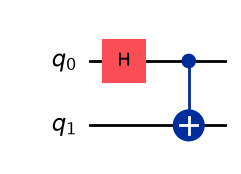

In [2]:
bell = QuantumCircuit(2)
bell.h(0)
bell.cx(0, 1)
bell.draw("mpl")

## Exact probabilities

The statevector simulator computes all amplitudes. Squared magnitudes give
measurement probabilities. This is a classical calculation of the ideal circuit,
not a readout of an actual quantum device's complete state.

Qiskit writes basis labels as $|q_1q_0\rangle$: qubit 0 is the **rightmost** bit.

In [3]:
state = Statevector.from_instruction(bell)
probabilities = state.probabilities_dict()
assert np.allclose(state.probabilities(), [0.5, 0, 0, 0.5])
print(probabilities)
state.draw("latex")

{np.str_('00'): np.float64(0.4999999999999999), np.str_('11'): np.float64(0.4999999999999999)}


<IPython.core.display.Latex object>

## Add measurements and take shots

Keep the unmeasured circuit for inspecting its state. Add terminal measurements
to a copy to show the experiment we would submit to a device. Each shot yields
one bitstring, and a histogram counts how often each bitstring occurs.

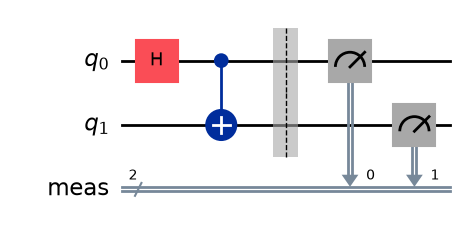

In [4]:
measured = bell.copy()
measured.measure_all()
measured.draw("mpl")

For this first notebook, sample directly from the statevector. The measurement
mapping is the one added by `measure_all()`. QDMI job submission comes later.

{np.str_('00'): np.int64(515), np.str_('11'): np.int64(509)}


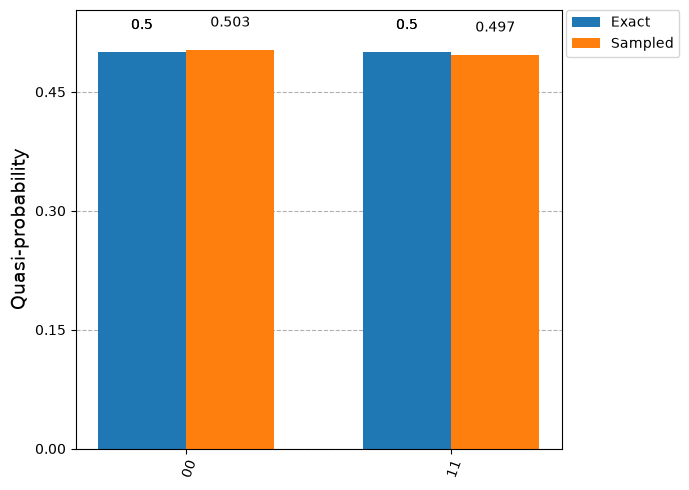

In [5]:
shots = 1024
state.seed(17)
counts = state.sample_counts(shots)
assert sum(counts.values()) == shots
assert set(counts) == {"00", "11"}
print(dict(counts))
plot_distribution([probabilities, counts], legend=["Exact", "Sampled"])

**Try it:** change `shots` to 32, then 8192. The probabilities remain the same.
What changes in the histogram? The seed makes each run reproducible.

## Check the bit order

With three qubits, flip only qubit 0. Predict the resulting bitstring before
running the next cell.

{np.str_('001'): np.float64(1.0)}


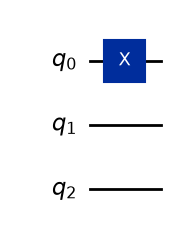

In [6]:
ordering = QuantumCircuit(3)
ordering.x(0)
ordering_state = Statevector.from_instruction(ordering)
assert ordering_state.probabilities_dict() == {"001": 1.0}
print(ordering_state.probabilities_dict())
ordering.draw("mpl")

## Exercise: extend the circuit to three qubits

Prepare $(|000\rangle+|111\rangle)/\sqrt{2}$, a three-qubit GHZ state.
Start from the two-qubit circuit and extend the controlled-X chain.

Use the cell below for your solution, then run the check. A solution is available
in the collapsed section.

<details>
<summary>Show a solution</summary>

```python
ghz = QuantumCircuit(3)
ghz.h(0)
ghz.cx(0, 1)
ghz.cx(1, 2)
```

</details>

In [7]:
ghz = None
# Replace None with your three-qubit circuit.

In [8]:
if ghz is None:
    print("Add your circuit in the previous cell, then rerun this check.")
else:
    assert ghz.num_qubits == 3
    ghz_state = Statevector.from_instruction(ghz)
    expected = np.zeros(8)
    expected[[0, 7]] = 0.5
    assert np.allclose(ghz_state.probabilities(), expected)
    # Probabilities alone cannot detect the relative phase.
    expected_state = np.zeros(8, dtype=complex)
    expected_state[[0, 7]] = 1 / np.sqrt(2)
    assert ghz_state.equiv(Statevector(expected_state))
    display(ghz.draw("mpl"))
    display(plot_distribution(ghz_state.probabilities_dict()))

Add your circuit in the previous cell, then rerun this check.


## Exercise: make phase visible

Both $H|0\rangle$ and $ZH|0\rangle$ give equal probabilities for 0 and 1.
But their relative phases differ. A final Hadamard turns that phase difference
into a different deterministic outcome.

Predict the results of $HH|0\rangle$ and $HZH|0\rangle$, then run the circuits.
Matrix products act from right to left, while circuit diagrams run left to right.

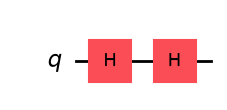

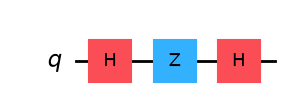

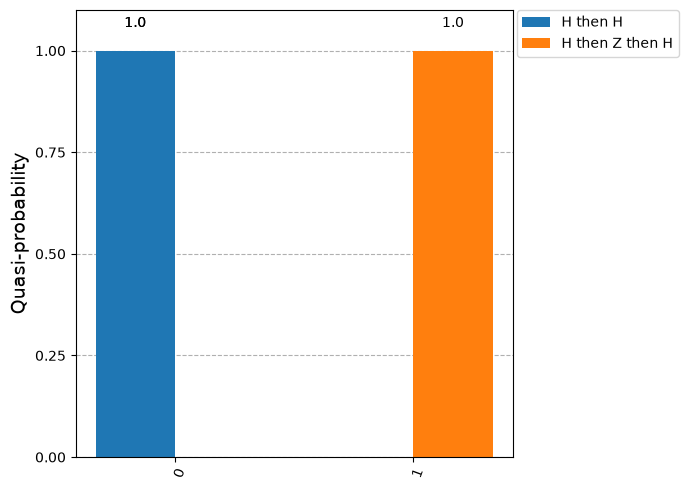

In [9]:
experiment_a = QuantumCircuit(1)
experiment_a.h(0)
experiment_a.h(0)

experiment_b = QuantumCircuit(1)
experiment_b.h(0)
experiment_b.z(0)
experiment_b.h(0)

state_a = Statevector.from_instruction(experiment_a)
state_b = Statevector.from_instruction(experiment_b)
assert np.allclose(state_a.probabilities(), [1, 0])
assert np.allclose(state_b.probabilities(), [0, 1])
display(experiment_a.draw("mpl"), experiment_b.draw("mpl"))
plot_distribution(
    [state_a.probabilities_dict(), state_b.probabilities_dict()],
    legend=["H then H", "H then Z then H"],
)

## Next: hand the circuit to the compiler

MQT Core can import the Qiskit circuit directly. This cell only imports and
inspects it. The next notebook follows the same small program through the
compiler's representations and transformations.

In [10]:
from mqt.core.mlir import QCProgram

program = QCProgram.from_qiskit(bell)
display(Code(program.ir, language="mlir"))

module {
  func.func @main() attributes {mqt.entry_point} {
    %alloc = memref.alloc() {mqt.register_name = "q"} : memref<2x!qc.qubit>
    %c0 = arith.constant 0 : index
    %q = memref.load %alloc[%c0] : memref<2x!qc.qubit>
    %c1 = arith.constant 1 : index
    %q_0 = memref.load %alloc[%c1] : memref<2x!qc.qubit>
    qc.h %q : !qc.qubit
    qc.ctrl(%q) targets (%q_1 = %q_0) {
      qc.x %q_1 : !qc.qubit
      qc.yield
    } : {!qc.qubit}, {!qc.qubit}
    memref.dealloc %alloc : memref<2x!qc.qubit>
    return
  }
}

Continue with [Follow a program through the compiler](https://mqt.readthedocs.io/projects/core/en/stable/tutorials/compiler_representations.html) after the compilation primer.
That notebook starts from OpenQASM so each tutorial still runs independently.